<a href="https://colab.research.google.com/github/roopvlogs18-lang/AIML-CODE/blob/main/AI_LAB_4_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")



All libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("stroke_processed_5k.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())



Saving stroke_processed_5k.csv to stroke_processed_5k (1).csv
Dataset loaded successfully!
Dataset Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


In [ ]:

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["stroke"].value_counts())

print("\nTarget Distribution in Percentage:")
print(df["stroke"].value_counts(normalize=True) * 100)



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB
None

Missing Values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_l

In [ ]:

X = df.drop("stroke", axis=1)
y = df["stroke"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())



Features Shape: (5110, 10)
Target Shape: (5110,)

Feature Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())



Training Data: (4088, 10)
Testing Data: (1022, 10)

Training Target Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing Target Distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [ ]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")


Feature scaling completed successfully!


In [ ]:

train_data = pd.DataFrame(X_train_scaled)
train_data["stroke"] = y_train.to_numpy()

majority = train_data[train_data["stroke"] == 0]
minority = train_data[train_data["stroke"] == 1]

minority_oversampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

balanced_data = pd.concat(
    [majority, minority_oversampled]
).sample(frac=1, random_state=42)

X_train_balanced = balanced_data.drop("stroke", axis=1).to_numpy()
y_train_balanced = balanced_data["stroke"].to_numpy()

print("Original Training Distribution:")
print(y_train.value_counts())

print("\nBalanced Training Distribution:")
print(pd.Series(y_train_balanced).value_counts())


Original Training Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Balanced Training Distribution:
0    3889
1    3889
Name: count, dtype: int64


In [ ]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ),

    "ANN (MLP)": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
}

print("Six machine learning models defined successfully!")



Six machine learning models defined successfully!


In [ ]:

results = []
predictions = {}
probabilities = {}
confusion_matrices = {}

for name, model in models.items():

    print(f"Training {name}...")

    # Train the model
    model.fit(X_train_balanced, y_train_balanced)

    # Predict test labels
    y_pred = model.predict(X_test_scaled)

    # Predict stroke probabilities
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    # Store predictions and probabilities
    predictions[name] = y_pred
    probabilities[name] = y_prob

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    confusion_matrices[name] = cm

    # Calculate evaluation metrics
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_test, y_pred
    )

    auc = roc_auc_score(
        y_test, y_prob
    )

    results.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Accuracy": accuracy,
        "AUC-ROC": auc
    })

print("\nAll six models trained successfully!")



Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM...
Training KNN...
Training ANN (MLP)...

All six models trained successfully!


In [ ]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="AUC-ROC",
    ascending=False
).reset_index(drop=True)

print("Performance Comparison of Six Models:")

display(
    results_df.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Accuracy": "{:.4f}",
        "AUC-ROC": "{:.4f}"
    })
)



Performance Comparison of Six Models:


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.1384,0.8000,0.2360,0.7466,0.8390
1,Random Forest,0.2917,0.1400,0.1892,0.9413,0.8133
2,SVM,0.1152,0.6200,0.1944,0.7485,0.7744
3,ANN (MLP),0.1168,0.3200,0.1711,0.8483,0.7736
4,Decision Tree,0.1149,0.5400,0.1895,0.7740,0.7091
5,KNN,0.0861,0.2600,0.1294,0.8288,0.6115


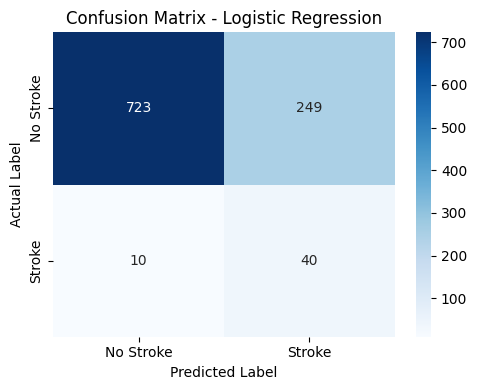

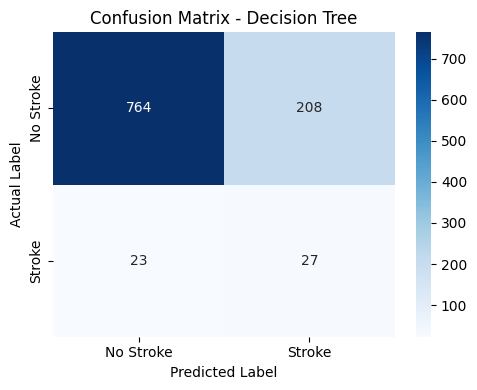

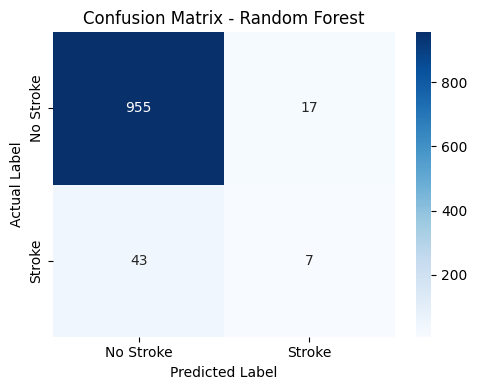

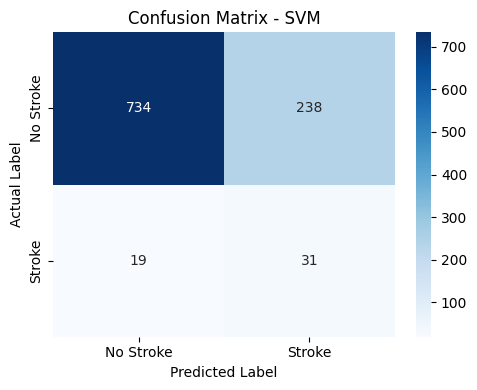

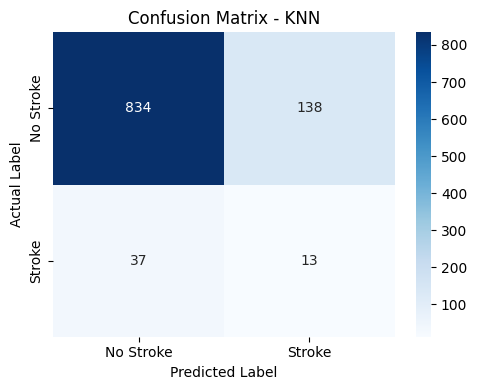

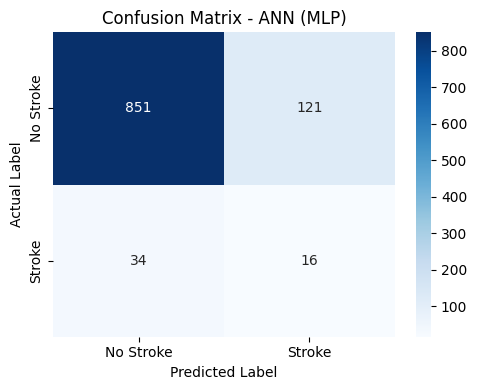

In [ ]:

for name, cm in confusion_matrices.items():

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()



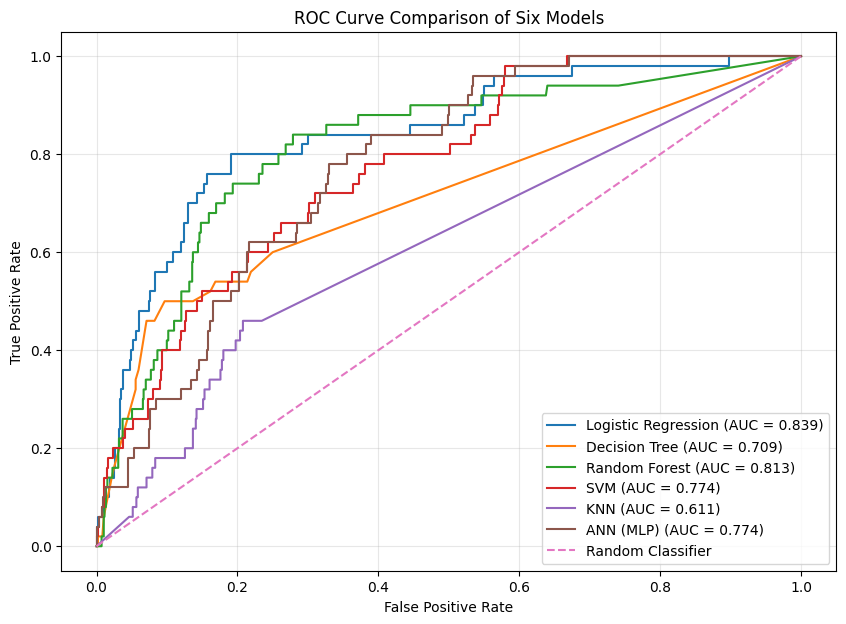

In [ ]:

plt.figure(figsize=(10, 7))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_value = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Six Models")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()



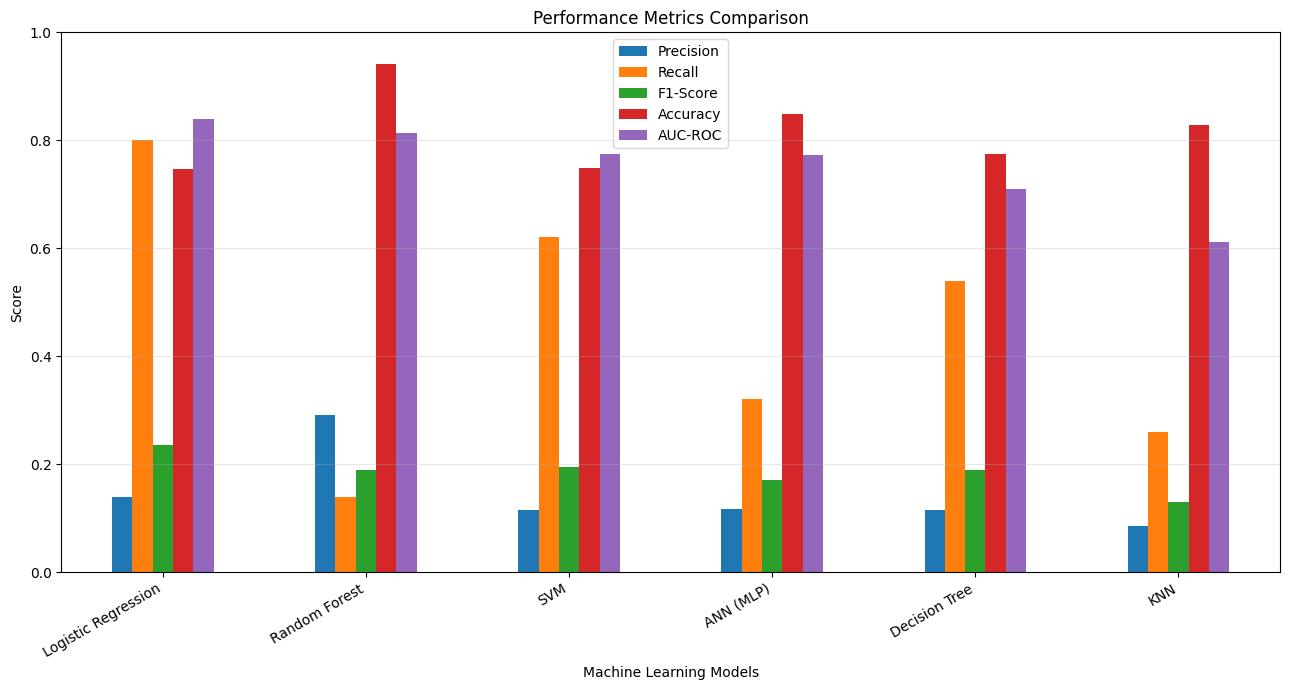

In [ ]:

metrics = [
    "Precision",
    "Recall",
    "F1-Score",
    "Accuracy",
    "AUC-ROC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title("Performance Metrics Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)

plt.xticks(rotation=30, ha="right")
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



In [ ]:

top_three = results_df.sort_values(
    by=["AUC-ROC", "Recall", "F1-Score"],
    ascending=False
).head(3).copy()

print("Top Three Models for Stroke Prediction:")

display(
    top_three.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Accuracy": "{:.4f}",
        "AUC-ROC": "{:.4f}"
    })
)



Top Three Models for Stroke Prediction:


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.1384,0.8000,0.2360,0.7466,0.8390
1,Random Forest,0.2917,0.1400,0.1892,0.9413,0.8133
2,SVM,0.1152,0.6200,0.1944,0.7485,0.7744


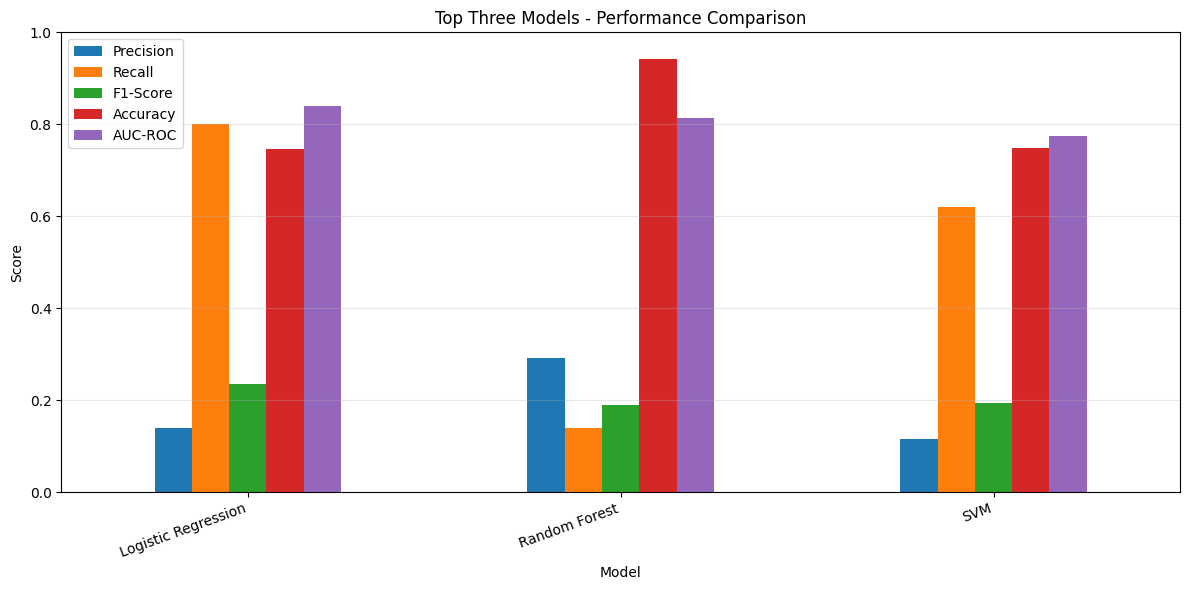


Confusion Matrix: Logistic Regression
                  Predicted No Stroke  Predicted Stroke
Actual No Stroke                  723               249
Actual Stroke                      10                40

Confusion Matrix: Random Forest
                  Predicted No Stroke  Predicted Stroke
Actual No Stroke                  955                17
Actual Stroke                      43                 7

Confusion Matrix: SVM
                  Predicted No Stroke  Predicted Stroke
Actual No Stroke                  734               238
Actual Stroke                      19                31


In [ ]:

top_three_names = top_three["Model"].tolist()

# Display top-three comparison
top_three.plot(
    x="Model",
    y=["Precision", "Recall", "F1-Score", "Accuracy", "AUC-ROC"],
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top Three Models - Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Display confusion matrices of top three
for name in top_three_names:

    cm = confusion_matrices[name]

    print(f"\nConfusion Matrix: {name}")

    print(
        pd.DataFrame(
            cm,
            index=["Actual No Stroke", "Actual Stroke"],
            columns=["Predicted No Stroke", "Predicted Stroke"]
        )
    )



In [ ]:

best_accuracy = results_df.loc[
    results_df["Accuracy"].idxmax()
]

best_precision = results_df.loc[
    results_df["Precision"].idxmax()
]

best_recall = results_df.loc[
    results_df["Recall"].idxmax()
]

best_f1 = results_df.loc[
    results_df["F1-Score"].idxmax()
]

best_auc = results_df.loc[
    results_df["AUC-ROC"].idxmax()
]

print("FINAL COMPARATIVE ANALYSIS")
print("=" * 50)

print(
    f"Best Accuracy: {best_accuracy['Model']} "
    f"({best_accuracy['Accuracy']:.4f})"
)

print(
    f"Best Precision: {best_precision['Model']} "
    f"({best_precision['Precision']:.4f})"
)

print(
    f"Best Recall: {best_recall['Model']} "
    f"({best_recall['Recall']:.4f})"
)

print(
    f"Best F1-Score: {best_f1['Model']} "
    f"({best_f1['F1-Score']:.4f})"
)

print(
    f"Best AUC-ROC: {best_auc['Model']} "
    f"({best_auc['AUC-ROC']:.4f})"
)

print("\nTop Three Models:")
print(top_three[["Model", "Recall", "F1-Score", "Accuracy", "AUC-ROC"]].to_string(index=False))



FINAL COMPARATIVE ANALYSIS
Best Accuracy: Random Forest (0.9413)
Best Precision: Random Forest (0.2917)
Best Recall: Logistic Regression (0.8000)
Best F1-Score: Logistic Regression (0.2360)
Best AUC-ROC: Logistic Regression (0.8390)

Top Three Models:
              Model  Recall  F1-Score  Accuracy  AUC-ROC
Logistic Regression    0.80  0.235988  0.746575 0.838971
      Random Forest    0.14  0.189189  0.941292 0.813272
                SVM    0.62  0.194357  0.748532 0.774424


In [ ]:

results_df.to_csv(
    "stroke_model_performance.csv",
    index=False
)

top_three.to_csv(
    "stroke_top_three_models.csv",
    index=False
)

print("Result files saved successfully!")

from google.colab import files

files.download("stroke_model_performance.csv")
files.download("stroke_top_three_models.csv")



Result files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>